# Phase 3 — Exploratory Data Analysis (BOXRR-23 head pose)

This notebook follows **Phase 3 of our planning document**. Every analysis listed there has its own section:

| Planning doc item | Section |
|---|---|
| Missing data / quality of retained recordings | 2 |
| Session duration, user distribution | 3 |
| Yaw/pitch/roll, quaternion, angular velocity & acceleration over time | 4 |
| Angular velocity, rotation distribution (which axes dominate) | 5 |
| Angular acceleration | 6 |
| Temporal patterns: stationary vs dynamic | 7 |
| Variability across individuals | 8 |
| Distribution of baseline prediction errors | 9 |
| **What this means for modeling** (motion size, history length, inputs) | 10 |
| Deliverables: user-level split, validation data loader, geodesic metric | 11 |
| Summary of findings | 12 |

**Task reminder:** input = last 400 head orientations (4 s at 100 Hz), output = next 20 (200 ms). Score = mean geodesic error at the **20th** predicted sample.

## Setup

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [29]:
import json, random, hashlib
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path("/kaggle/input/datasets/chaitanyapeshin/headvane-boxrr23-preprocessed")   # ← folder that contains users/
SAMPLE_FILES = 300                               # files loaded fully for motion analysis
SEED = 0

FS = 100          # Hz
CONTEXT = 400     # input samples (4 s)
HORIZON = 20      # output samples (200 ms)

In [28]:
def find_segments(f):
    """All groups in an .h5 file that contain a 'quaternions' dataset."""
    groups = []
    f.visititems(lambda name, obj: groups.append(obj)
                 if isinstance(obj, h5py.Group) and "quaternions" in obj else None)
    return groups

def load_file(path):
    """Return a list of segments: dict(user, session, q = (N,4) w,x,y,z, t = (N,) seconds)."""
    out = []
    with h5py.File(path, "r") as f:
        for g in find_segments(f):
            out.append({
                "user": str(g.attrs.get("user_id", Path(path).parent.name)),
                "session": str(g.attrs.get("session_id", Path(path).stem)),
                "q": g["quaternions"][:].astype(np.float64),
                "t": g["timestamps"][:] if "timestamps" in g else None,
            })
    return out

def rot(q_wxyz):
    """(N,4) w,x,y,z → scipy Rotation."""
    return R.from_quat(q_wxyz[:, [1, 2, 3, 0]])

def angular_velocity(q_wxyz):
    """Angular velocity in the head frame, deg/s, shape (N-1, 3) = (pitch, yaw, roll) rates."""
    r = rot(q_wxyz)
    return np.degrees((r[:-1].inv() * r[1:]).as_rotvec()) * FS

def yaw_pitch_roll(q_wxyz):
    yaw, pitch, roll = rot(q_wxyz).as_euler("YXZ", degrees=True).T
    return np.degrees(np.unwrap(np.radians(yaw))), pitch, roll

def geodesic_deg(q_pred, q_true):
    """Official metric: 2·acos(|q̂·q|) in degrees (works for any quaternion order)."""
    return np.degrees(2 * np.arccos(np.clip(np.abs(np.sum(q_pred * q_true, axis=-1)), 0, 1)))

In [10]:
# Side files that came with the dataset
for name in ["corpus_summary.json", "acquisition_audit.json"]:
    if (ROOT / name).exists():
        print(f"--- {name}"); print(json.dumps(json.loads((ROOT / name).read_text()), indent=2)[:1500])
if (ROOT / "segment_index.csv").exists():
    display(pd.read_csv(ROOT / "segment_index.csv").head())

--- corpus_summary.json
{
  "release": "v1",
  "sample_rate_hz": 100,
  "quaternion_order": [
    "w",
    "x",
    "y",
    "z"
  ],
  "segments": 112109,
  "samples": 1654118646,
  "users_with_retained_data": 13364,
  "motion_hours": 4594.774016666666,
  "known_limitations": "Provisional release. Some archives have recording or worker errors. Includes successfully saved segments from partially successful archives."
}
--- acquisition_audit.json
{
  "revision": "af25be3ef76b176fbee0a094e82d97a611f9c950",
  "pipeline_sha256": "78b4c3a930e2147ff8667945c1e9e709ca95fc82e113b3e0c425a13dc8e3686b",
  "discovered": 105852,
  "completed": 105632,
  "remaining": 220,
  "completed_before_run": 96785,
  "newly_completed": 8847,
  "failed_this_run": {
    "1bb66ba5-693f-491f-9163-db7d98e36d1e": {
      "path": "users/1/1bb66ba5-693f-491f-9163-db7d98e36d1e.tar",
      "error": "Missing output or recording-level errors in receipt",
      "log": "reports/corpus/full_dataset/logs/1bb66ba5-693f-491f-916

,hdf5,segment,user_id,session_id,samples
0,users/00/000637b7-4ae4-4844-9c8d-db28a855abf7.h5,000637b7-4ae4-4844-9c8d-db28a855abf7/0b4dd796-...,000637b7-4ae4-4844-9c8d-db28a855abf7,0b4dd796-eccf-469d-8943-075d30ab204a,19771
1,users/00/000637b7-4ae4-4844-9c8d-db28a855abf7.h5,000637b7-4ae4-4844-9c8d-db28a855abf7/0bb1f6fe-...,000637b7-4ae4-4844-9c8d-db28a855abf7,0bb1f6fe-17c4-4431-8c8b-e9f87653afe2,18396
2,users/00/000637b7-4ae4-4844-9c8d-db28a855abf7.h5,000637b7-4ae4-4844-9c8d-db28a855abf7/0bb1f6fe-...,000637b7-4ae4-4844-9c8d-db28a855abf7,0bb1f6fe-17c4-4431-8c8b-e9f87653afe2,2422
3,users/00/000637b7-4ae4-4844-9c8d-db28a855abf7.h5,000637b7-4ae4-4844-9c8d-db28a855abf7/1d25390d-...,000637b7-4ae4-4844-9c8d-db28a855abf7,1d25390d-6b30-48a0-8ad7-1f131263d158,26452
4,users/00/000637b7-4ae4-4844-9c8d-db28a855abf7.h5,000637b7-4ae4-4844-9c8d-db28a855abf7/2259a81e-...,000637b7-4ae4-4844-9c8d-db28a855abf7,2259a81e-d096-4e6f-a770-3d5f2fd64fdb,21715


In [11]:
# Sanity check of the metric: 30° apart → 30°; q and −q are the same rotation → 0°
a = np.array([1.0, 0, 0, 0])
b = R.from_euler("y", 30, degrees=True).as_quat()[[3, 0, 1, 2]]
print(geodesic_deg(a, b), geodesic_deg(a, -a))

29.999999999999993 0.0


In [12]:
# Load a random sample of files completely (motion analysis uses these)
all_files = sorted(ROOT.rglob("*.h5"))
sample_files = random.Random(SEED).sample(all_files, min(SAMPLE_FILES, len(all_files)))
segments = [s for p in sample_files for s in load_file(p)]
print(f"{len(all_files):,} files in total; loaded {len(sample_files)} files = {len(segments):,} segments "
      f"from {len({s['user'] for s in segments})} users")

13,364 files in total; loaded 300 files = 2,910 segments from 300 users


## 2. Data quality (missing data, cleanliness)

The preprocessing should guarantee: no NaNs, unit-norm quaternions, an exact 10 ms time grid, and no sign flips between neighbouring samples (q and −q are the same rotation, but a flip would confuse a model). Gaps in the original recordings are **not interpolated** — they split a session into several segments, so *segments per session* tells us how gappy the raw data was.

In [15]:
quality = []
for s in segments:
    q, t = s["q"], s["t"]
    quality.append({
        "has_nan": np.isnan(q).any(),
        "max_norm_error": np.abs(np.linalg.norm(q, axis=1) - 1).max(),
        "sign_flips": int((np.sum(q[1:] * q[:-1], axis=1) < 0).sum()),
        "max_step_error_ms": np.abs(np.diff(t) - 1 / FS).max() * 1000 if t is not None else np.nan,
    })
quality = pd.DataFrame(quality)
print("segments with NaN:          ", quality.has_nan.sum())
print("max |‖q‖ − 1|:              ", f"{quality.max_norm_error.max():.1e}")
print("segments with sign flips:   ", (quality.sign_flips > 0).sum())
print("max deviation from 10 ms:   ", f"{quality.max_step_error_ms.max():.4f} ms")

segments with NaN:           0
max |‖q‖ − 1|:               4.3e-08
segments with sign flips:    0
max deviation from 10 ms:    0.0000 ms


## 3. Session duration and user distribution (all files)

For this we only need segment lengths and IDs, not the data itself, so we can cover **every** file quickly.

In [ ]:
# rows = []
# for p in all_files:
#     with h5py.File(p, "r") as f:
#         for g in find_segments(f):
#             rows.append({"user": str(g.attrs.get("user_id", p.parent.name)),
#                          "session": str(g.attrs.get("session_id", p.stem)),
#                          "samples": g["quaternions"].shape[0]})
# index = pd.DataFrame(rows)
# index["seconds"] = index.samples / FS
# index["windows"] = (index.samples - CONTEXT - HORIZON + 1).clip(lower=0)

# per_session = index.groupby("session").agg(user=("user", "first"), segments=("samples", "size"), seconds=("seconds", "sum"))
# per_user = index.groupby("user").agg(sessions=("session", "nunique"), minutes=("seconds", lambda s: s.sum() / 60))

# print(f"users:    {index.user.nunique():,}")
# print(f"sessions: {index.session.nunique():,}")
# print(f"segments: {len(index):,}")
# print(f"hours:    {index.seconds.sum() / 3600:,.1f}")
# print(f"training windows (400 → 20, stride 1): {index.windows.sum():,}")
# display(pd.DataFrame({"segment length (s)": index.seconds.describe(),
#                       "session length (s)": per_session.seconds.describe(),
#                       "segments per session": per_session.segments.describe(),
#                       "sessions per user": per_user.sessions.describe(),
#                       "minutes per user": per_user.minutes.describe()}).round(1))

In [18]:
import multiprocessing as mp, time

CACHE = Path("/kaggle/working/segment_lengths.csv")

def scan_file(p):
    """Segment lengths + IDs of one file (reads metadata only, no data)."""
    out = []
    try:
        with h5py.File(p, "r") as f:
            for g in find_segments(f):
                out.append({"user": str(g.attrs.get("user_id", p.parent.name)),
                            "session": str(g.attrs.get("session_id", p.stem)),
                            "samples": g["quaternions"].shape[0]})
    except Exception as e:
        print("skip", p.name, e)
    return out

COLS = {"user": None, "session": None, "samples": None, "seconds": None}

def from_segment_index():
    path = ROOT / "segment_index.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path)
    print("segment_index.csv columns:", list(df.columns)); display(df.head(3))

    numeric = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    def pick(role, words, among):
        if COLS[role]:
            return COLS[role]
        return next((c for c in among if any(w in c.lower() for w in words)), None)

    user    = pick("user",    ["user"], df.columns)
    session = pick("session", ["session", "replay", "recording"], [c for c in df.columns if c != user])
    samples = pick("samples", ["sample", "length", "frames", "num", "count", "size"], numeric)
    seconds = pick("seconds", ["duration", "second"], numeric)
    print(f"using → user: {user}, session: {session}, samples: {samples}, seconds: {seconds}")

    if not (user and session and (samples or seconds)):
        print("→ needed columns not found, falling back to scanning files")
        return None
    n = df[samples] if samples else (df[seconds] * FS).round()
    return pd.DataFrame({"user": df[user].astype(str), "session": df[session].astype(str),
                         "samples": n.astype(int)})

if CACHE.exists():
    index = pd.read_csv(CACHE, dtype={"user": str, "session": str}); print("loaded cache")
else:
    index = from_segment_index()
    if index is None:
        t0, rows = time.time(), []
        with mp.get_context("fork").Pool(8) as pool:
            for i, r in enumerate(pool.imap_unordered(scan_file, all_files, chunksize=16), 1):
                rows += r
                if i % 1000 == 0:
                    print(f"{i:,}/{len(all_files):,} files  ({i / (time.time() - t0):.0f}/s)")
        index = pd.DataFrame(rows)
    index.to_csv(CACHE, index=False)

index["seconds"] = index.samples / FS
index["windows"] = (index.samples - CONTEXT - HORIZON + 1).clip(lower=0)
per_session = index.groupby("session").agg(user=("user", "first"), segments=("samples", "size"), seconds=("seconds", "sum"))
per_user = index.groupby("user").agg(sessions=("session", "nunique"), minutes=("seconds", lambda s: s.sum() / 60))

print(f"users:    {index.user.nunique():,}")
print(f"sessions: {index.session.nunique():,}")
print(f"segments: {len(index):,}")
print(f"hours:    {index.seconds.sum() / 3600:,.1f}")
print(f"training windows (400 → 20, stride 1): {index.windows.sum():,}")
display(pd.DataFrame({"segment length (s)": index.seconds.describe(),
                      "session length (s)": per_session.seconds.describe(),
                      "segments per session": per_session.segments.describe(),
                      "sessions per user": per_user.sessions.describe(),
                      "minutes per user": per_user.minutes.describe()}).round(1))

segment_index.csv columns: ['hdf5', 'segment', 'user_id', 'session_id', 'samples']


,hdf5,segment,user_id,session_id,samples
0,users/00/000637b7-4ae4-4844-9c8d-db28a855abf7.h5,000637b7-4ae4-4844-9c8d-db28a855abf7/0b4dd796-...,000637b7-4ae4-4844-9c8d-db28a855abf7,0b4dd796-eccf-469d-8943-075d30ab204a,19771
1,users/00/000637b7-4ae4-4844-9c8d-db28a855abf7.h5,000637b7-4ae4-4844-9c8d-db28a855abf7/0bb1f6fe-...,000637b7-4ae4-4844-9c8d-db28a855abf7,0bb1f6fe-17c4-4431-8c8b-e9f87653afe2,18396
2,users/00/000637b7-4ae4-4844-9c8d-db28a855abf7.h5,000637b7-4ae4-4844-9c8d-db28a855abf7/0bb1f6fe-...,000637b7-4ae4-4844-9c8d-db28a855abf7,0bb1f6fe-17c4-4431-8c8b-e9f87653afe2,2422


using → user: user_id, session: session_id, samples: samples, seconds: None
users:    13,364
sessions: 102,815
segments: 112,109
hours:    4,594.8
training windows (400 → 20, stride 1): 1,607,144,975


,segment length (s),session length (s),segments per session,sessions per user,minutes per user
count,112109.0,102815.0,102815.0,13364.0,13364.0
mean,147.5,160.9,1.1,7.7,20.6
std,81.4,81.4,0.6,27.1,79.2
min,10.0,10.0,1.0,1.0,0.2
25%,87.2,113.2,1.0,1.0,2.8
50%,158.3,169.5,1.0,2.0,5.1
75%,202.6,209.3,1.0,5.0,13.3
max,4938.4,4986.1,100.0,789.0,2372.0


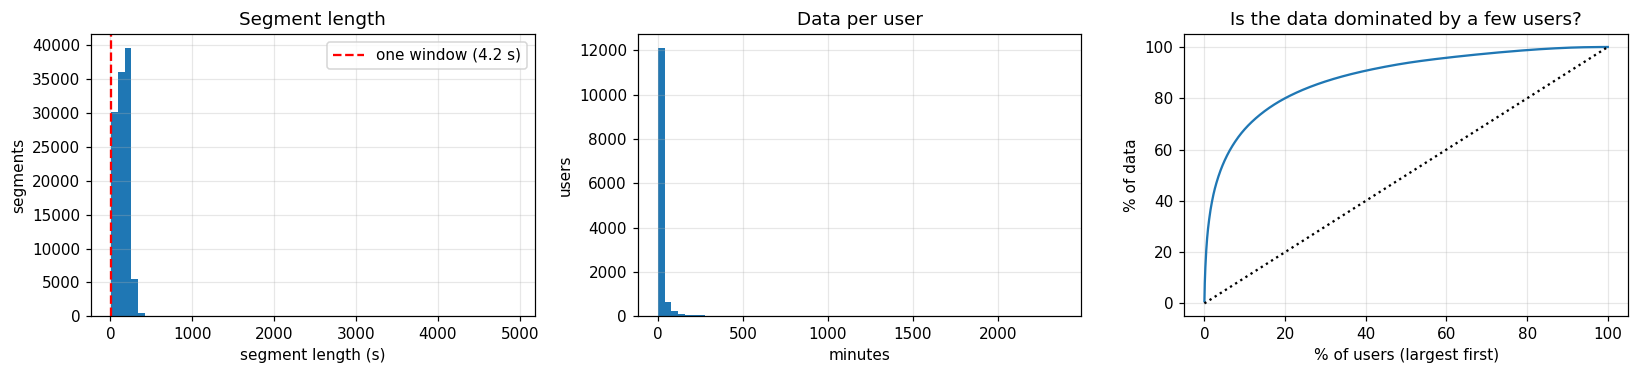

The top 10 % of users hold 68 % of all data.


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(index.seconds, bins=60); ax[0].axvline((CONTEXT + HORIZON) / FS, color="r", ls="--", label="one window (4.2 s)")
ax[0].set(xlabel="segment length (s)", ylabel="segments", title="Segment length"); ax[0].legend()
ax[1].hist(per_user.minutes, bins=60); ax[1].set(xlabel="minutes", ylabel="users", title="Data per user")
share = per_user.minutes.sort_values(ascending=False).cumsum() / per_user.minutes.sum() * 100
ax[2].plot(np.linspace(0, 100, len(share)), share.values); ax[2].plot([0, 100], [0, 100], "k:")
ax[2].set(xlabel="% of users (largest first)", ylabel="% of data", title="Is the data dominated by a few users?")
plt.tight_layout(); plt.show()
top10 = share.iloc[max(1, len(share) // 10) - 1]
print(f"The top 10 % of users hold {top10:.0f} % of all data.")

## 4. What does head motion look like? (one example segment)

Yaw / pitch / roll, the raw quaternion components, angular velocity and angular acceleration over 10 seconds.
**Re-run this cell** to see a different random segment.

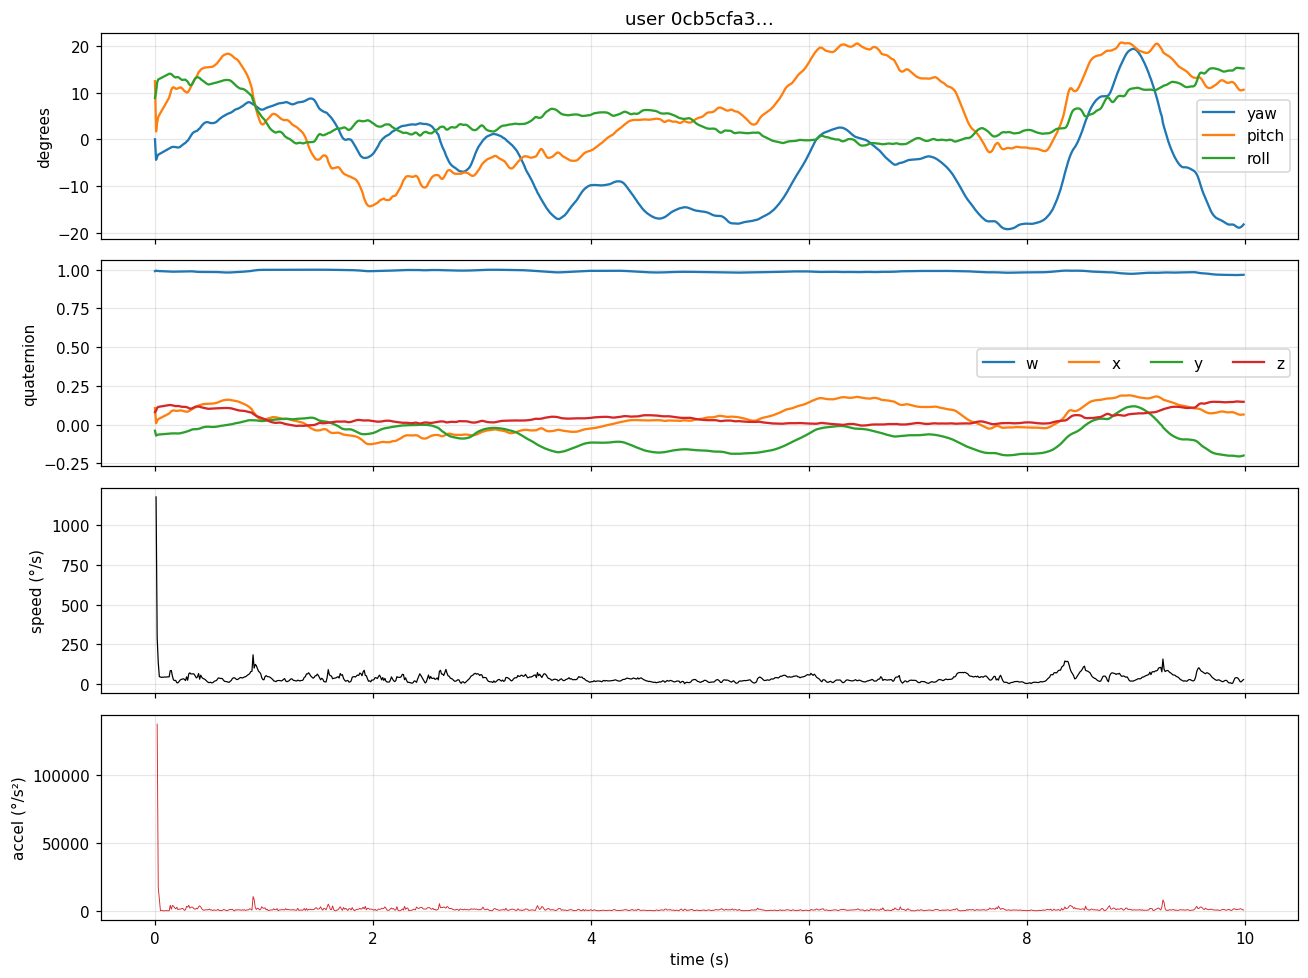

In [20]:
s = random.choice([s for s in segments if len(s["q"]) >= 1000])
q = s["q"][:1000]
t = np.arange(len(q)) / FS
yaw, pitch, roll = yaw_pitch_roll(q)
omega = angular_velocity(q)
speed = np.linalg.norm(omega, axis=1)
accel = np.linalg.norm(np.diff(omega, axis=0), axis=1) * FS

fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
ax[0].plot(t, yaw - yaw[0], label="yaw"); ax[0].plot(t, pitch, label="pitch"); ax[0].plot(t, roll, label="roll")
ax[0].set(ylabel="degrees", title=f"user {s['user'][:8]}…"); ax[0].legend()
for i, c in enumerate("wxyz"): ax[1].plot(t, q[:, i], label=c)
ax[1].set(ylabel="quaternion"); ax[1].legend(ncol=4)
ax[2].plot(t[1:], speed, "k", lw=0.8); ax[2].set(ylabel="speed (°/s)")
ax[3].plot(t[2:], accel, "tab:red", lw=0.6); ax[3].set(ylabel="accel (°/s²)", xlabel="time (s)")
plt.tight_layout(); plt.show()## 5. Angular velocity — how fast, and along which axis?

## 5. Angular velocity — how fast, and along which axis?

In [32]:
# omega_all = np.concatenate([angular_velocity(s["q"]) for s in segments])   # (N, 3): pitch, yaw, roll rate
# speed_all = np.linalg.norm(omega_all, axis=1)

# print("angular speed (°/s) percentiles:")
# print(pd.Series(speed_all).describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(1).to_string())

# fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
# ax[0].hist(speed_all, bins=np.logspace(-1, 3, 100)); ax[0].set_xscale("log")
# ax[0].set(xlabel="angular speed (°/s, log scale)", ylabel="samples", title="Angular speed")
# for i, name in enumerate(["pitch", "yaw", "roll"]):
#     ax[1].hist(omega_all[:, i], bins=200, range=(-300, 300), histtype="step", label=name, log=True)
# ax[1].set(xlabel="rate (°/s)", title="Rate per axis"); ax[1].legend()
# plt.tight_layout(); plt.show()

# rms = np.sqrt((omega_all ** 2).mean(axis=0))
# print("RMS rate per axis (°/s):", dict(zip(["pitch", "yaw", "roll"], rms.round(1))))
# print("share of motion energy:  ", dict(zip(["pitch", "yaw", "roll"], (rms**2 / (rms**2).sum() * 100).round(0))), "%")

39,620,672 samples (110.1 h); plotting a random 3,000,000
angular speed (°/s) percentiles:
10%     14.8
25%     24.3
50%     39.7
75%     62.3
90%     91.9
95%    115.8
99%    181.1


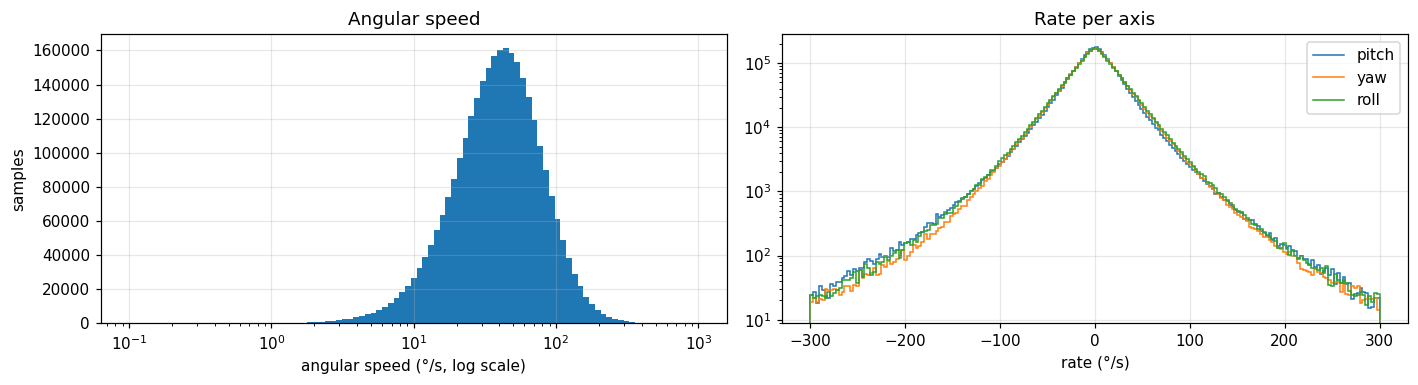

RMS rate per axis (°/s): {'pitch': np.float64(34.8), 'yaw': np.float64(35.0), 'roll': np.float64(36.1)}
share of motion energy:   {'pitch': np.float64(32.0), 'yaw': np.float64(33.0), 'roll': np.float64(35.0)} %


In [26]:
def angular_velocity(q):
    """Head-frame angular velocity (deg/s), shape (N-1, 3) = (pitch, yaw, roll) rates.
    Relative rotation conj(q_t) · q_{t+1}, converted to a rotation vector. q is (N,4) w,x,y,z."""
    aw, ax, ay, az = q[:-1].T
    bw, bx, by, bz = q[1:].T
    w = aw*bw + ax*bx + ay*by + az*bz
    x = aw*bx - ax*bw - ay*bz + az*by
    y = aw*by + ax*bz - ay*bw - az*bx
    z = aw*bz - ax*by + ay*bx - az*bw
    sign = np.where(w < 0, -1.0, 1.0)                      # shortest rotation
    v = np.stack([x, y, z], axis=1) * sign[:, None]
    n = np.linalg.norm(v, axis=1)
    scale = np.where(n > 1e-12, 2 * np.arctan2(n, w * sign) / np.maximum(n, 1e-12), 2.0)
    return (np.degrees(v * scale[:, None]) * FS).astype(np.float32)

# Angular velocity for every loaded segment, computed once and reused below
for s in segments:
    s["omega"] = angular_velocity(s["q"])

omega_all = np.concatenate([s["omega"] for s in segments])       # (N, 3): pitch, yaw, roll rate
speed_all = np.linalg.norm(omega_all, axis=1)

# Plots and percentiles don't need every sample: a random 3 M is plenty
rng = np.random.default_rng(SEED)
pick = rng.choice(len(speed_all), size=min(3_000_000, len(speed_all)), replace=False)
omega_s, speed_s = omega_all[pick], speed_all[pick]
print(f"{len(speed_all):,} samples ({len(speed_all) / FS / 3600:.1f} h); plotting a random {len(pick):,}")

print("angular speed (°/s) percentiles:")
p = [10, 25, 50, 75, 90, 95, 99]
print(pd.Series(np.percentile(speed_s, p), index=[f"{x}%" for x in p]).round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
bins = np.logspace(-1, 3, 100)
ax[0].stairs(np.histogram(speed_s, bins)[0], bins, fill=True); ax[0].set_xscale("log")
ax[0].set(xlabel="angular speed (°/s, log scale)", ylabel="samples", title="Angular speed")
bins = np.linspace(-300, 300, 201)
for i, name in enumerate(["pitch", "yaw", "roll"]):
    ax[1].stairs(np.histogram(omega_s[:, i], bins)[0], bins, label=name)
ax[1].set_yscale("log"); ax[1].set(xlabel="rate (°/s)", title="Rate per axis"); ax[1].legend()
plt.tight_layout(); plt.show()

rms = np.sqrt((omega_all.astype(np.float64) ** 2).mean(axis=0))     # full data, cheap
print("RMS rate per axis (°/s):", dict(zip(["pitch", "yaw", "roll"], rms.round(1))))
print("share of motion energy:  ", dict(zip(["pitch", "yaw", "roll"], (rms**2 / (rms**2).sum() * 100).round(0))), "%")

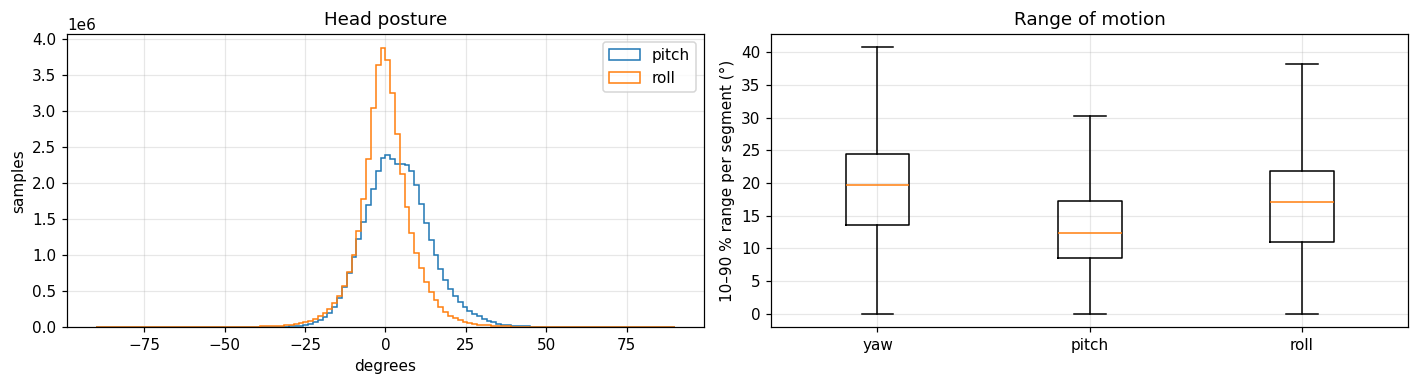

median 10–90 % range per segment (°): {'yaw': 19.6, 'pitch': 12.4, 'roll': 17.0}


In [36]:
# Rotation distribution: where does the head point, and how much does it sweep?
ypr = [yaw_pitch_roll(s["q"]) for s in segments]
pitch_all = np.concatenate([p for _, p, _ in ypr]); roll_all = np.concatenate([r for _, _, r in ypr])
sweep = pd.DataFrame([{n: np.percentile(a, 90) - np.percentile(a, 10) for n, a in zip(["yaw", "pitch", "roll"], v)} for v in ypr])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(pitch_all, bins=120, range=(-90, 90), histtype="step", label="pitch")
ax[0].hist(roll_all, bins=120, range=(-90, 90), histtype="step", label="roll")
ax[0].set(xlabel="degrees", ylabel="samples", title="Head posture"); ax[0].legend()
ax[1].boxplot([sweep[c] for c in sweep], tick_labels=sweep.columns, showfliers=False)
ax[1].set(ylabel="10–90 % range per segment (°)", title="Range of motion")
plt.tight_layout(); plt.show()

print("median 10–90 % range per segment (°):", sweep.median().round(1).to_dict())

## 6. Angular acceleration — how abruptly does motion change?

angular acceleration (°/s²) percentiles:
count    39617762.0
mean         1395.0
std          1598.0
min             0.0
50%           970.0
90%          2859.0
99%          7172.0
max        216484.0


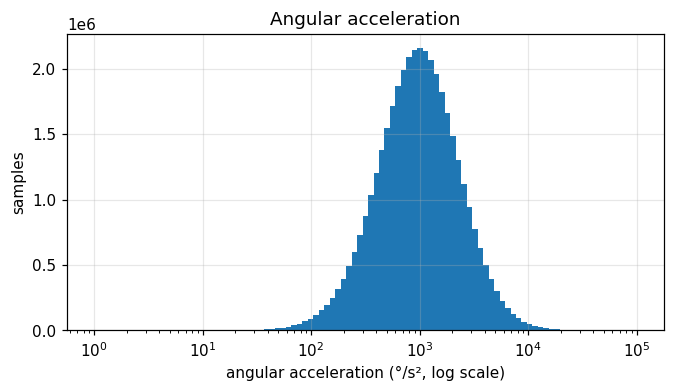

In [37]:
# accel_all = np.concatenate([np.linalg.norm(np.diff(angular_velocity(s["q"]), axis=0), axis=1) * FS for s in segments])
# print("angular acceleration (°/s²) percentiles:")
# print(pd.Series(accel_all).describe(percentiles=[.5, .9, .99]).round(0).to_string())
# plt.figure(figsize=(7, 3.5))
# plt.hist(accel_all, bins=np.logspace(0, 5, 100)); plt.xscale("log")
# plt.xlabel("angular acceleration (°/s², log scale)"); plt.ylabel("samples"); plt.title("Angular acceleration")
# plt.show()

angular acceleration (°/s²) percentiles:
50%     969.0
90%    2889.0
99%    7324.0


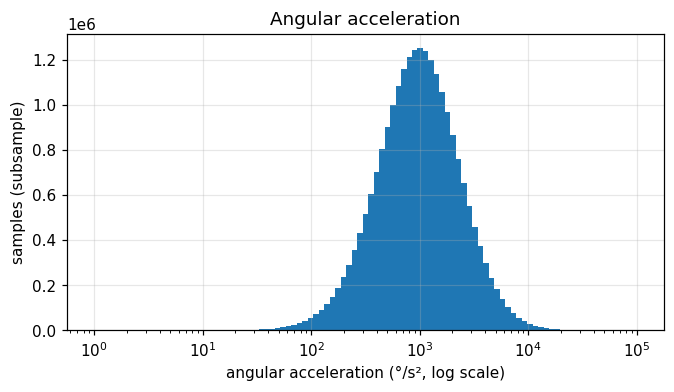

In [38]:
rng = np.random.default_rng(SEED)
accel_s = []
for s in segments:
    omega = s["omega"] if "omega" in s else angular_velocity(s["q"])
    a = np.linalg.norm(np.diff(omega, axis=0), axis=1) * FS            # deg/s²
    k = rng.choice(len(a), size=min(10_000, len(a)), replace=False)
    accel_s.append(a[k])
accel_s = np.concatenate(accel_s)

p = [50, 90, 99]
print("angular acceleration (°/s²) percentiles:")
print(pd.Series(np.percentile(accel_s, p), index=[f"{x}%" for x in p]).round(0).to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.logspace(0, 5, 100)
ax.stairs(np.histogram(accel_s, bins)[0], bins, fill=True)              # much faster than plt.hist
ax.set_xscale("log")
ax.set(xlabel="angular acceleration (°/s², log scale)", ylabel="samples (subsample)", title="Angular acceleration")
plt.show()

> High acceleration = the head changes direction or starts/stops. A constant-velocity predictor cannot handle these moments — they are where a learned model can win.

## 7. Temporal patterns — stationary vs dynamic

We label each sample by its speed: **still** (< 5 °/s), **slow** (5–50), **moving** (50–150), **fast** (> 150).

still      1.0
slow      62.3
moving    34.7
fast       2.0

still periods: median 0.01 s, 90th pct 0.04 s, longest 25.7 s


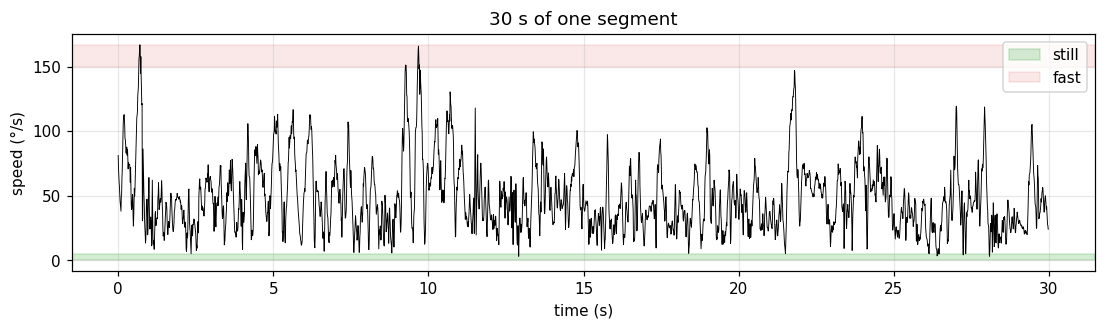

In [24]:
labels = pd.Series(pd.cut(speed_all, [0, 5, 50, 150, np.inf], labels=["still", "slow", "moving", "fast"], right=False))
print((labels.value_counts(normalize=True, sort=False) * 100).round(1).to_string())

# How long do still periods last?
still = speed_all < 5
edges = np.flatnonzero(np.diff(np.r_[0, still.astype(int), 0]))
runs = (edges[1::2] - edges[::2]) / FS
if len(runs):
    print(f"\nstill periods: median {np.median(runs):.2f} s, 90th pct {np.percentile(runs, 90):.2f} s, longest {runs.max():.1f} s")

# One segment coloured by regime
s = random.choice([s for s in segments if len(s["q"]) >= 3000])
sp = np.linalg.norm(angular_velocity(s["q"][:3000]), axis=1)
plt.figure(figsize=(12, 2.8)); plt.plot(np.arange(len(sp)) / FS, sp, "k", lw=0.6)
plt.axhspan(0, 5, color="tab:green", alpha=0.2, label="still"); plt.axhspan(150, max(sp.max(), 151), color="tab:red", alpha=0.1, label="fast")
plt.xlabel("time (s)"); plt.ylabel("speed (°/s)"); plt.title("30 s of one segment"); plt.legend(); plt.show()

## 8. Variability across individuals

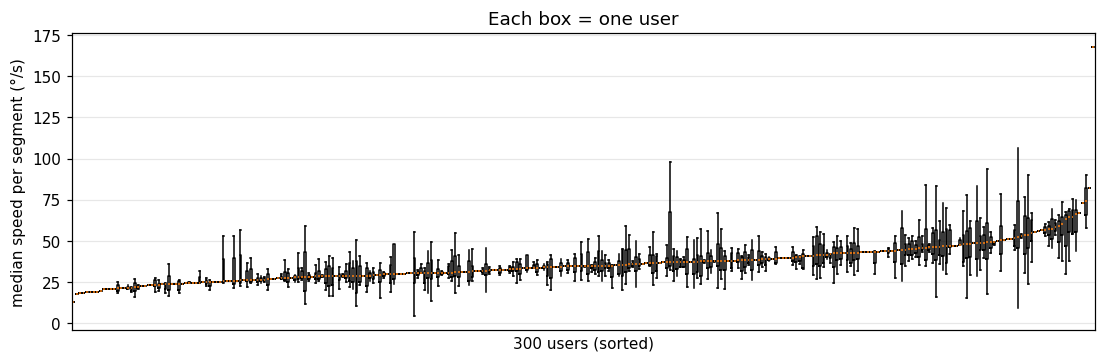

slowest user median 12.7 °/s, fastest 167.9 °/s


In [39]:
user_speed = pd.DataFrame([{"user": s["user"], "speed": np.median(np.linalg.norm(angular_velocity(s["q"]), axis=1))} for s in segments])
order = user_speed.groupby("user").speed.median().sort_values().index
plt.figure(figsize=(12, 3.5))
plt.boxplot([user_speed.speed[user_speed.user == u] for u in order], showfliers=False)
plt.xticks([]); plt.xlabel(f"{len(order)} users (sorted)"); plt.ylabel("median speed per segment (°/s)")
plt.title("Each box = one user"); plt.show()
print(f"slowest user median {user_speed.groupby('user').speed.median().min():.1f} °/s, "
      f"fastest {user_speed.groupby('user').speed.median().max():.1f} °/s")

## 9. Baseline prediction errors

The planning doc requires a **constant-velocity** baseline. We evaluate:

* **Last observation** — the head stays where it is.
* **Constant velocity** — keep rotating at the speed of the last step.

Windows are task-shaped (400 in, 20 out), one every 0.5 s. We show error at **100 ms (10th sample)** as listed in the planning doc and at **200 ms (20th sample)**, which is what the challenge scores.

In [40]:
def baseline_windows(q, stride=50):
    """Errors (W, 20) for both baselines on all windows of one segment."""
    ends = np.arange(CONTEXT - 1, len(q) - HORIZON, stride)       # index of last input sample
    if len(ends) == 0: return None
    r = rot(q)
    future = q[ends[:, None] + np.arange(1, HORIZON + 1)]           # (W, 20, 4)
    last = q[ends][:, None, :]
    err_last = geodesic_deg(np.broadcast_to(last, future.shape), future)
    step = (r[ends - 1].inv() * r[ends]).as_rotvec()                 # rotation per sample (head frame)
    pred = np.stack([(r[ends] * R.from_rotvec(step * h)).as_quat()[:, [3, 0, 1, 2]]
                     for h in range(1, HORIZON + 1)], axis=1)
    err_cv = geodesic_deg(pred, future)
    speed_now = np.degrees(np.linalg.norm(step, axis=1)) * FS
    return err_last, err_cv, speed_now

res = [x for x in (baseline_windows(s["q"]) for s in segments) if x is not None]
err_last = np.concatenate([r[0] for r in res]); err_cv = np.concatenate([r[1] for r in res])
speed_now = np.concatenate([r[2] for r in res])

table = pd.DataFrame({
    "last observation": [err_last[:, 9].mean(), err_last[:, 19].mean(), np.median(err_last[:, 19]), np.percentile(err_last[:, 19], 95)],
    "constant velocity": [err_cv[:, 9].mean(), err_cv[:, 19].mean(), np.median(err_cv[:, 19]), np.percentile(err_cv[:, 19], 95)],
}, index=["mean @100 ms", "mean @200 ms (score)", "median @200 ms", "p95 @200 ms"]).round(2)
print(f"{len(err_cv):,} windows"); display(table)

769,566 windows


,last observation,constant velocity
mean @100 ms,4.16,3.48
mean @200 ms (score),7.28,8.19
median @200 ms,5.90,6.49
p95 @200 ms,17.53,20.23


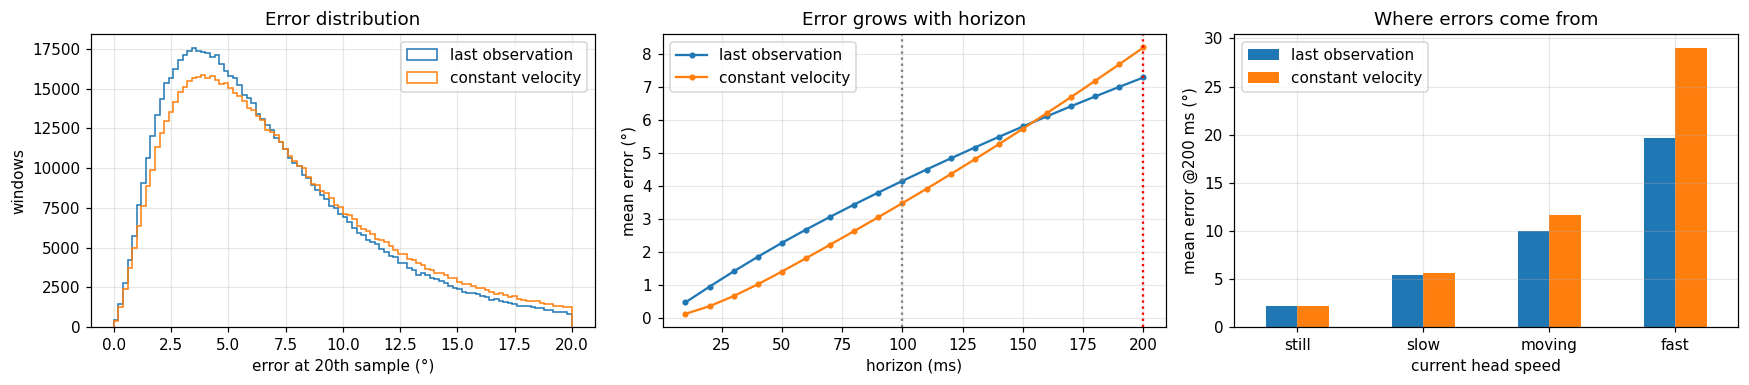

,last observation,constant velocity,share_of_windows_pct
still,2.23,2.23,0.9
slow,5.46,5.67,62.2
moving,9.95,11.62,34.8
fast,19.64,28.99,2.0


In [41]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].hist(err_last[:, 19], bins=100, range=(0, 20), histtype="step", label="last observation")
ax[0].hist(err_cv[:, 19], bins=100, range=(0, 20), histtype="step", label="constant velocity")
ax[0].set(xlabel="error at 20th sample (°)", ylabel="windows", title="Error distribution"); ax[0].legend()
ms = np.arange(1, HORIZON + 1) * 10
ax[1].plot(ms, err_last.mean(0), marker=".", label="last observation"); ax[1].plot(ms, err_cv.mean(0), marker=".", label="constant velocity")
ax[1].axvline(100, color="gray", ls=":"); ax[1].axvline(200, color="r", ls=":")
ax[1].set(xlabel="horizon (ms)", ylabel="mean error (°)", title="Error grows with horizon"); ax[1].legend()
bands = pd.Series(pd.cut(speed_now, [0, 5, 50, 150, np.inf], labels=["still", "slow", "moving", "fast"], right=False))
by_band = pd.DataFrame({"last observation": err_last[:, 19], "constant velocity": err_cv[:, 19]}).groupby(bands, observed=False).mean()
by_band.plot.bar(ax=ax[2], rot=0); ax[2].set(xlabel="current head speed", ylabel="mean error @200 ms (°)", title="Where errors come from")
plt.tight_layout(); plt.show()
display(by_band.round(2).assign(share_of_windows_pct=(bands.value_counts(normalize=True, sort=False) * 100).round(1).values))

## 10. What this means for modeling

Three questions that directly shape the model design:

1. **How big is the motion we have to predict?** (output scale)
2. **How much history is actually useful?** (context length — shorter context = lower latency, which is 30 % of the score)
3. **What should the model see as input?** (absolute orientation vs relative motion)

In [42]:
# 1. Rotation between the last input and the 20th future sample = what the model must predict
delta = err_last[:, 19]   # identical to "how far the head moves in 200 ms"
print("rotation over the next 200 ms (°):")
print(pd.Series(delta).describe(percentiles=[.25, .5, .75, .9, .99]).round(2).to_string())

rotation over the next 200 ms (°):
count    769566.00
mean          7.28
std           5.61
min           0.00
25%           3.54
50%           5.90
75%           9.42
90%          13.95
99%          27.15
max         177.22


/tmp/ipykernel_50/1837702209.py:8: RuntimeWarning: invalid value encountered in scalar divide
  ac += [np.sum(w[:len(w) - L] * w[L:]) / np.sum(w * w) * len(w) / (len(w) - L) for L in lags]; n += 1


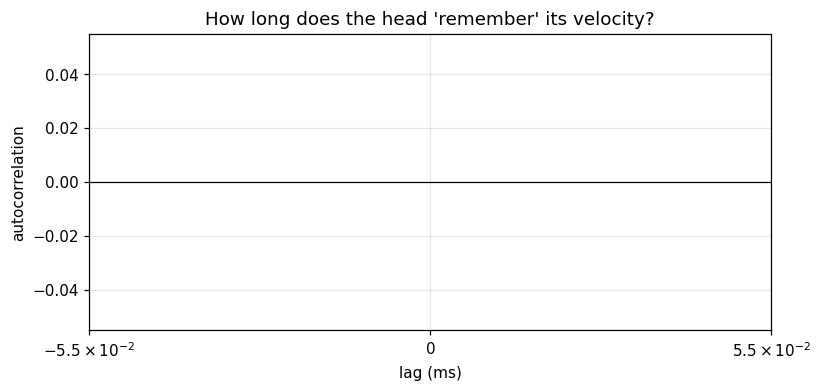

correlation stays above 0.5 for 4 s


In [52]:
# 2. How long does motion stay predictable? Autocorrelation of angular velocity
lags = np.r_[0:20:2, 20:100:10, 100:401:25]              # samples (10 ms each)
ac = np.zeros(len(lags)); n = 0
for s in segments:
    w = angular_velocity(s["q"])
    if len(w) <= lags[-1]: continue
    w = w - w.mean(0)
    ac += [np.sum(w[:len(w) - L] * w[L:]) / np.sum(w * w) * len(w) / (len(w) - L) for L in lags]; n += 1
ac /= n
plt.figure(figsize=(8, 3.5)); plt.plot(lags * 10, ac, marker="o")
plt.axhline(0, color="k", lw=0.8); plt.xscale("symlog", linthresh=100)
plt.xlabel("lag (ms)"); plt.ylabel("autocorrelation"); plt.title("How long does the head 'remember' its velocity?")
plt.show()
half = lags[np.argmax(ac < 0.5)] * 10 if (ac < 0.5).any() else None
print(f"velocity correlation drops below 0.5 after ~{half} ms" if half else "correlation stays above 0.5 for 4 s")

In [53]:
len(segments)

2910

used 2909 segments, skipped 1 (no motion / invalid)


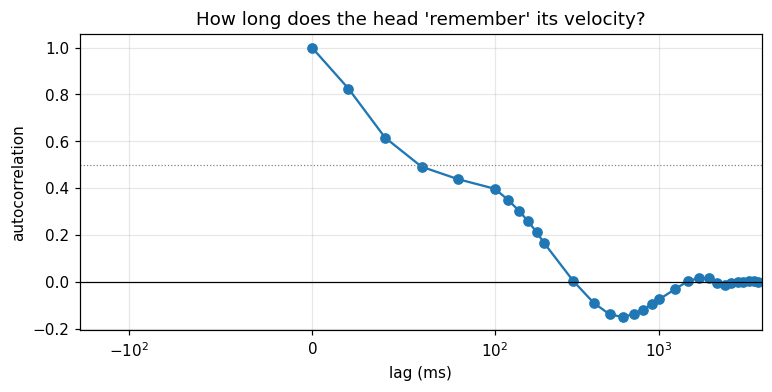

velocity correlation drops below 0.5 after ~60 ms


In [55]:
# 2. How long does motion stay predictable? Autocorrelation of angular velocity
lags = np.r_[0:20:2, 20:100:10, 100:401:25]                 # samples (10 ms each)
long_segs = [s for s in segments if len(s["q"]) > lags[-1] + 2]
chosen = long_segs #random.Random(SEED).sample(long_segs, min(200, len(long_segs)))

curves, skipped, skipped_seg = [], 0, []
for s in chosen:
    w = (s["omega"] if "omega" in s else angular_velocity(s["q"])).astype(np.float64)
    w = w - w.mean(axis=0)
    energy = np.sum(w * w)
    if not np.isfinite(energy) or energy < 1e-9:              # motionless or broken segment
        skipped += 1
        skipped_seg.append(s)
        continue
    n = len(w)
    curves.append([np.sum(w[:n - L] * w[L:]) / energy * n / (n - L) for L in lags])

ac = np.mean(curves, axis=0)
print(f"used {len(curves)} segments, skipped {skipped} (no motion / invalid)")

plt.figure(figsize=(8, 3.5))
plt.plot(lags * 10, ac, marker="o")
plt.axhline(0, color="k", lw=0.8); plt.axhline(0.5, color="gray", ls=":", lw=0.8)
plt.xscale("symlog", linthresh=100)
plt.xlabel("lag (ms)"); plt.ylabel("autocorrelation")
plt.title("How long does the head 'remember' its velocity?")
plt.show()

half = lags[np.argmax(ac < 0.5)] * 10 if (ac < 0.5).any() else None
print(f"velocity correlation drops below 0.5 after ~{half} ms" if half else "correlation stays above 0.5 for 4 s")

In [56]:
skipped_seg

[{'user': '172c14d2-4dfc-4338-ac64-3a9821906e23',
  'session': '232c07d3-50e1-467a-84e9-8ff31f9b3dab',
  'q': array([[1., 0., 0., 0.],
         [1., 0., 0., 0.],
         [1., 0., 0., 0.],
         ...,
         [1., 0., 0., 0.],
         [1., 0., 0., 0.],
         [1., 0., 0., 0.]]),
  't': array([133.55419922, 133.56419922, 133.57419922, ..., 159.15419922,
         159.16419922, 159.17419922]),
  'omega': array([[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         ...,
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]], dtype=float32)}]

> If the correlation dies out well before 4 s, a **shorter context** (e.g. 100–200 samples) may lose little accuracy while cutting latency and compute. This is the context-length ablation listed in Phase 5/6 — the curve above tells us which lengths are worth testing.

In [44]:
# 3. Input representation: absolute orientation varies hugely between sessions, relative motion does not
first = np.array([s["q"][0] for s in segments])
yaw0 = rot(first).as_euler("YXZ", degrees=True)[:, 0]
print(f"starting yaw across segments: std {yaw0.std():.0f}° (range {yaw0.min():.0f}…{yaw0.max():.0f}°)")
print(f"per-step rotation (10 ms):    median {np.median(speed_all) / FS:.3f}°, p99 {np.percentile(speed_all, 99) / FS:.2f}°")

starting yaw across segments: std 14° (range -178…179°)
per-step rotation (10 ms):    median 0.397°, p99 1.81°


> Absolute heading is essentially arbitrary (it depends on where the player stood), while per-step motion is small and consistent. This suggests feeding the model orientations **relative to the last input sample** (or angular velocities) and predicting the **change** from the last orientation, then converting back to absolute (w, x, y, z) at the output boundary.

## 11. Deliverables — user-level split and validation data loader

The planning doc forbids random window splits: **every user goes entirely to train or to validation**. A stable hash of the user ID makes the split reproducible for the whole team.

In [45]:
def split_of(user, val_fraction=0.1):
    h = int(hashlib.sha256(user.encode()).hexdigest()[:8], 16) / 16**8
    return "val" if h < val_fraction else "train"

per_user["split"] = [split_of(u) for u in per_user.index]
display(per_user.groupby("split").agg(users=("sessions", "size"), sessions=("sessions", "sum"), hours=("minutes", lambda m: m.sum() / 60)).round(1))
per_user[["split"]].to_csv("user_split.csv")
print("saved user_split.csv")

,users,sessions,hours
split,,,
train,12007,92548,4141.0
val,1357,10267,453.8


saved user_split.csv


In [46]:
def make_windows(segments, split, stride=20):
    """Build (context, target) pairs for one split.
    X: (N, 400, 4)  Y: (N, 20, 4)  — float32, quaternion order w,x,y,z (challenge interface)."""
    X, Y = [], []
    for s in segments:
        if split_of(s["user"]) != split: continue
        q = s["q"].astype(np.float32)
        for start in range(0, len(q) - CONTEXT - HORIZON + 1, stride):
            X.append(q[start:start + CONTEXT]); Y.append(q[start + CONTEXT:start + CONTEXT + HORIZON])
    return np.stack(X), np.stack(Y)

X_val, Y_val = make_windows(segments, "val")
print("validation windows:", X_val.shape, Y_val.shape)

# Check: the loader + metric reproduce the last-observation baseline
print(f"last-observation error @20th sample on val: {geodesic_deg(X_val[:, -1], Y_val[:, -1]).mean():.2f}°")

validation windows: (243392, 400, 4) (243392, 20, 4)
last-observation error @20th sample on val: 7.51°


## 12. Summary of findings

In [47]:
energy = rms**2 / (rms**2).sum() * 100
summary = pd.Series({
    "users / sessions / hours": f"{index.user.nunique():,} / {index.session.nunique():,} / {index.seconds.sum() / 3600:,.0f} h",
    "training windows (stride 1)": f"{index.windows.sum():,}",
    "data quality issues": "none" if (quality.has_nan.sum() == 0 and (quality.sign_flips > 0).sum() == 0) else "see section 2",
    "top 10 % users hold": f"{top10:.0f} % of data",
    "median head speed": f"{np.median(speed_all):.1f} °/s",
    "dominant axis": f"{['pitch', 'yaw', 'roll'][int(np.argmax(rms))]} ({energy.max():.0f} % of motion energy)",
    "time still (< 5 °/s)": f"{(speed_all < 5).mean() * 100:.0f} %",
    "median motion in 200 ms": f"{np.median(delta):.2f}°",
    "velocity memory (corr > 0.5)": f"~{half} ms" if half else "> 4 s",
    "last observation @200 ms": f"{err_last[:, 19].mean():.2f}°",
    "constant velocity @200 ms": f"{err_cv[:, 19].mean():.2f}°  ← the number to beat",
})
display(summary.to_frame("finding"))

,finding
users / sessions / hours,"13,364 / 102,815 / 4,595 h"
training windows (stride 1),"1,607,144,975"
data quality issues,none
top 10 % users hold,68 % of data
median head speed,39.7 °/s
dominant axis,roll (35 % of motion energy)
time still (< 5 °/s),1 %
median motion in 200 ms,5.90°
velocity memory (corr > 0.5),> 4 s
last observation @200 ms,7.28°


**Implications for Phase 4–6**

1. **Target to beat:** constant-velocity error at the 20th sample (table above). The paper must report it.
2. **Where to gain:** errors concentrate in fast motion and direction changes (section 9) — model capacity should go there; still periods are already easy.
3. **Context length:** use the autocorrelation curve (section 10) to pick lengths for the ablation; shorter context = lower latency.
4. **Inputs/outputs:** relative orientation or angular velocity in, change of orientation out (section 10).
5. **Training data:** if a few users dominate (section 3), cap windows per user so the model generalises to unseen users.
6. **Validation:** always on held-out users (section 11).